In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import kagglehub
import os
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import pickle
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import os
path=kagglehub.dataset_download("snap/amazon-fine-food-reviews")
print(f"path : {path}")
csv_file=os.path.join(path,"Reviews.csv")
df=pd.read_csv(csv_file)
df.head(2)

Using Colab cache for faster access to the 'amazon-fine-food-reviews' dataset.
path : /kaggle/input/amazon-fine-food-reviews


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   Id                      568454 non-null  int64 
 1   ProductId               568454 non-null  object
 2   UserId                  568454 non-null  object
 3   ProfileName             568428 non-null  object
 4   HelpfulnessNumerator    568454 non-null  int64 
 5   HelpfulnessDenominator  568454 non-null  int64 
 6   Score                   568454 non-null  int64 
 7   Time                    568454 non-null  int64 
 8   Summary                 568427 non-null  object
 9   Text                    568454 non-null  object
dtypes: int64(5), object(5)
memory usage: 43.4+ MB


In [ ]:
df.isnull().sum()

,0
Id,0
ProductId,0
UserId,0
ProfileName,26
HelpfulnessNumerator,0
HelpfulnessDenominator,0
Score,0
Time,0
Summary,27
Text,0


In [ ]:
df_clean=df[['Text','Score']]
df_clean.head(2)

,Text,Score
0,I have bought several of the Vitality canned d...,5
1,Product arrived labeled as Jumbo Salted Peanut...,1


In [ ]:
df_clean.isnull().sum()

,0
Text,0
Score,0


In [ ]:
score_count=df_clean['Score'].value_counts().sort_index()
for score,count in score_count.items():
  percentage=(count/len(df_clean))*100
  print(f"{score} stars : {percentage:.2f} %")

1 stars : 9.19 %
2 stars : 5.24 %
3 stars : 7.50 %
4 stars : 14.19 %
5 stars : 63.88 %


In [ ]:
for score in range(1,6):
  sample_review= df_clean[df_clean['Score']== score]['Text'].iloc[0]
  print(f"\n {score} - STAR REVIEW: ")
  print(f" '{sample_review}' ")


 1 - STAR REVIEW: 
 'Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if the vendor intended to represent the product as "Jumbo".' 

 2 - STAR REVIEW: 
 'If you are looking for the secret ingredient in Robitussin I believe I have found it.  I got this in addition to the Root Beer Extract I ordered (which was good) and made some cherry soda.  The flavor is very medicinal.' 

 3 - STAR REVIEW: 
 'This seems a little more wholesome than some of the supermarket brands, but it is somewhat mushy and doesn't have quite as much flavor either.  It didn't pass muster with my kids, so I probably won't buy it again.' 

 4 - STAR REVIEW: 
 'This is a confection that has been around a few centuries.  It is a light, pillowy citrus gelatin with nuts - in this case Filberts. And it is cut into tiny squares and then liberally coated with powdered sugar.  And it is a tiny mouthful of heaven.  Not too chewy, and very flavor

In [ ]:
df_clean['text_length']=df_clean['Text'].str.len()
df_clean['word_count']=df_clean['Text'].str.split().str.len()

In [ ]:
df_clean.head(2)

,Text,Score,text_length,word_count
0,I have bought several of the Vitality canned d...,5,263,48
1,Product arrived labeled as Jumbo Salted Peanut...,1,190,31


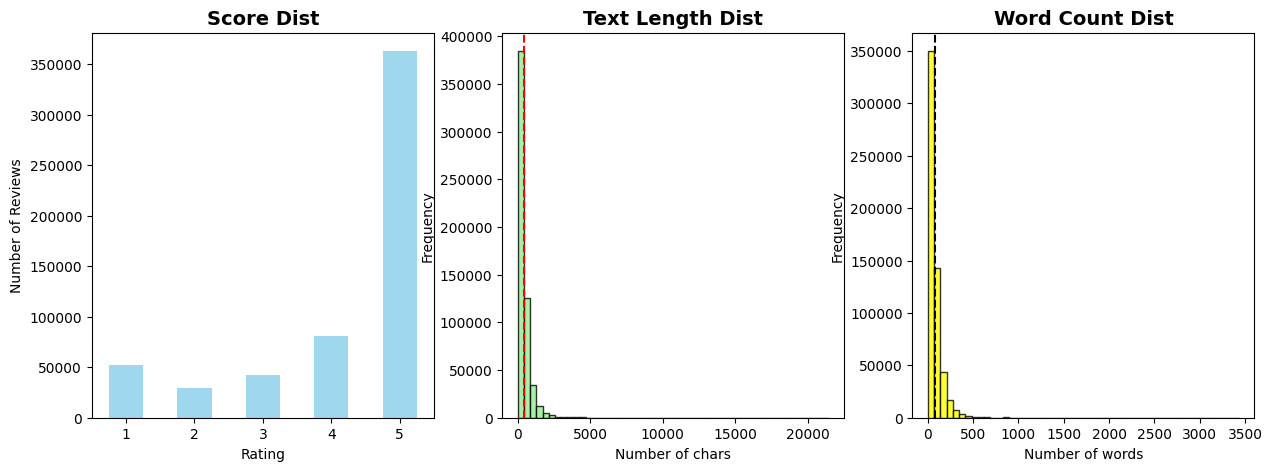

In [ ]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
score_count.plot(kind='bar',color='skyblue',alpha=0.8)
plt.title('Score Dist',fontsize=14,fontweight='bold')
plt.xlabel('Rating')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=0)

plt.subplot(1,3,2)
df_clean['text_length'].plot(kind='hist',bins=50,color='lightgreen',alpha=0.8,edgecolor='black')
plt.title('Text Length Dist',fontsize=14,fontweight='bold')
plt.xlabel('Number of chars')
plt.ylabel('Frequency')
plt.axvline(df_clean['text_length'].mean(),color='red',linestyle='--',label=f"Mean: {df_clean['text_length'].mean():.2f}")

plt.subplot(1,3,3)
df_clean['word_count'].plot(kind='hist',bins=50,color='yellow',alpha=0.8,edgecolor='black')
plt.title('Word Count Dist',fontsize=14,fontweight='bold')
plt.xlabel('Number of words')
plt.ylabel('Frequency')
plt.axvline(df_clean['word_count'].mean(),color='black',linestyle='--',label=f"Mean: {df_clean['word_count'].mean():.2f}")

In [ ]:
df_binary=df_clean[df_clean['Score']!=3].copy()
df_binary['sentiment']=(df_binary['Score']>=4).astype(int)
df_binary.head(2)

,Text,Score,text_length,word_count,sentiment
0,I have bought several of the Vitality canned d...,5,263,48,1
1,Product arrived labeled as Jumbo Salted Peanut...,1,190,31,0


In [ ]:
#class imbalance
from sklearn.utils import resample
neg_reviews=df_binary[df_binary['sentiment']==0]
pos_reviews=df_binary[df_binary['sentiment']==1]

print("Original Imbalance")
neg_per=(sum(df_binary['sentiment']==0)/len(df_binary))*100
pos_per=(sum(df_binary['sentiment']==1)/len(df_binary))*100
print(f"Negative reviews : {neg_per:.2f} %")
print(f"Positive reviews : {pos_per:.2f} %")

n_minority=len(neg_reviews)
pos_downsampled=resample(pos_reviews,replace=False,n_samples=n_minority,random_state=42)
df_balanced=pd.concat([neg_reviews,pos_downsampled])
df_balanced=df_balanced.sample(frac=1,random_state=42).reset_index(drop=True)

print("After Imbalance")
neg_per=(sum(df_balanced['sentiment']==0)/len(df_balanced))*100
pos_per=(sum(df_balanced['sentiment']==1)/len(df_balanced))*100
print(f"Negative reviews : {neg_per:.2f} %")
print(f"Positive reviews : {pos_per:.2f} %")

Original Imbalance
Negative reviews : 15.60 %
Positive reviews : 84.40 %
After Imbalance
Negative reviews : 50.00 %
Positive reviews : 50.00 %


In [ ]:
#Text cleaning
import re
def clean_text(text):
  text=text.lower()
  text=re.sub(r'[^a-zA-Z\s]','',text) # Remove non-alphabetic characters except spaces
  text=' '.join(text.split())
  return text

In [ ]:
df_balanced['Clean_Text']=df_balanced['Text'].apply(clean_text)
df_balanced.head(5)

,Text,Score,text_length,word_count,sentiment,Clean_Text
0,"First of all, let me say that my dog likes the...",2,453,85,0,first of all let me say that my dog likes the ...
1,"I had really high hopes for this coffee, it sm...",1,364,73,0,i had really high hopes for this coffee it sme...
2,I have tried all the varieties of Special K ce...,1,221,42,0,i have tried all the varieties of special k ce...
3,I placed an order for Dogswell Happy Hips for ...,1,991,187,0,i placed an order for dogswell happy hips for ...
4,"I usually dont like black herbal tea, but this...",5,316,64,1,i usually dont like black herbal tea but this ...


In [ ]:
MAX_FEATURES=1000
MAX_LENGTH=100

x=df_balanced['Clean_Text'].values#features
y=df_balanced['sentiment'].values#target

tokenizer=Tokenizer(num_words=MAX_FEATURES,oov_token='<OOV>')
tokenizer.fit_on_texts(x)
x_seq=tokenizer.texts_to_sequences(x)


In [ ]:
x_padded=pad_sequences(x_seq,maxlen=MAX_LENGTH,padding='post',truncating='post')
print(x_padded[0],end=',')

[ 97   8  40 420  49 168  13  14  95 568   2  32   8   9 256   5 190 169
   3  18   5 377   1   1  72   1  95 406  62   1   9   1 256  81  45 406
  34 603   7   4 534   7 278  69   2  68 215 487 126  55  14   1   1 440
   7  78  42 875  26   5   1   1 264 273   6  77 141   1  19  98  55   8
 454  37 646   3 396  79   7  17  14   1 440   7   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0],

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x_padded,y,test_size=0.20,random_state=42,stratify=y)

In [ ]:
#DEFINE RNN MODEL
def create_rnn_model():
  model=Sequential([
      Embedding(input_dim=MAX_FEATURES,output_dim=128,input_length=MAX_LENGTH),
      SimpleRNN(units=64,return_sequences=False),
      Dropout(0.5),
      Dense(64,activation='relu'),
      Dense(32,activation='relu'),
      Dense(1,activation='sigmoid')

  ])
  return model

rnn_model=create_rnn_model()
rnn_model.compile(optimizer=Adam(learning_rate=0.01),
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

In [ ]:
rnn_history=rnn_model.fit(x_train,y_train,
                          batch_size=128,
                          epochs=5,validation_split=0.2)

Epoch 1/5
821/821 ━━━━━━━━━━━━━━━━━━━━ 67s 78ms/step - accuracy: 0.5178 - loss: 0.6937 - val_accuracy: 0.5293 - val_loss: 0.6920
Epoch 2/5
821/821 ━━━━━━━━━━━━━━━━━━━━ 60s 73ms/step - accuracy: 0.5263 - loss: 0.6905 - val_accuracy: 0.5363 - val_loss: 0.6888
Epoch 3/5
821/821 ━━━━━━━━━━━━━━━━━━━━ 86s 77ms/step - accuracy: 0.5179 - loss: 0.6914 - val_accuracy: 0.4969 - val_loss: 0.6925
Epoch 4/5
821/821 ━━━━━━━━━━━━━━━━━━━━ 81s 75ms/step - accuracy: 0.5043 - loss: 0.6928 - val_accuracy: 0.5091 - val_loss: 0.6935
Epoch 5/5
821/821 ━━━━━━━━━━━━━━━━━━━━ 64s 78ms/step - accuracy: 0.5224 - loss: 0.6904 - val_accuracy: 0.5218 - val_loss: 0.6903


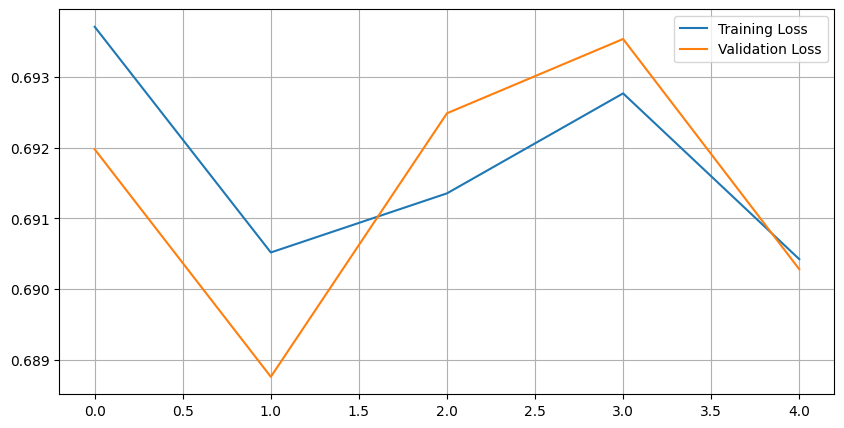

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(rnn_history.history['loss'],label='Training Loss')
plt.plot(rnn_history.history['val_loss'],label='Validation Loss')
plt.legend()
plt.grid()

In [ ]:
#DEFINE LSTM MODEL
def create_lstm_model():
  model=Sequential([
      Embedding(input_dim=MAX_FEATURES,output_dim=128,input_length=MAX_LENGTH),
      LSTM(units=64,return_sequences=False),
      Dropout(0.5),
      Dense(64,activation='relu'),
      Dense(32,activation='relu'),
      Dense(1,activation='sigmoid')

  ])
  return model

lstm_model=create_lstm_model()
lstm_model.compile(optimizer=Adam(learning_rate=0.01),
                    loss='binary_crossentropy',
                    metrics=['accuracy'])

In [ ]:
lstm_history=lstm_model.fit(x_train,y_train,
                          batch_size=128,
                          epochs=5,validation_split=0.2)

Epoch 1/5
821/821 ━━━━━━━━━━━━━━━━━━━━ 194s 232ms/step - accuracy: 0.7331 - loss: 0.5039 - val_accuracy: 0.8567 - val_loss: 0.3360
Epoch 2/5
821/821 ━━━━━━━━━━━━━━━━━━━━ 200s 244ms/step - accuracy: 0.8579 - loss: 0.3384 - val_accuracy: 0.8631 - val_loss: 0.3187
Epoch 3/5
821/821 ━━━━━━━━━━━━━━━━━━━━ 197s 238ms/step - accuracy: 0.8673 - loss: 0.3182 - val_accuracy: 0.8612 - val_loss: 0.3235
Epoch 4/5
821/821 ━━━━━━━━━━━━━━━━━━━━ 187s 228ms/step - accuracy: 0.8677 - loss: 0.3191 - val_accuracy: 0.8674 - val_loss: 0.3208
Epoch 5/5
821/821 ━━━━━━━━━━━━━━━━━━━━ 203s 247ms/step - accuracy: 0.8690 - loss: 0.3135 - val_accuracy: 0.8726 - val_loss: 0.3064


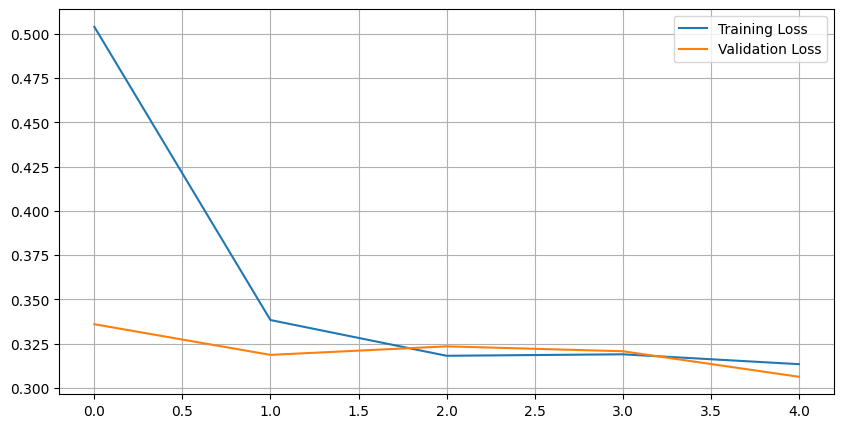

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(lstm_history.history['loss'],label='Training Loss')
plt.plot(lstm_history.history['val_loss'],label='Validation Loss')
plt.legend()
plt.grid()